### Get data

In [1]:
import numpy as np
import scipy.optimize as opt
import matplotlib.pyplot as plt

/home/gea/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
# Generazione casuale dati
np.random.seed(42) 
n_points = 20
true_xc, true_yc, true_R = 5, 5, 3
angles = np.random.uniform (0,2*np.pi,n_points)
x = true_xc + true_R* np.cos(angles) + np.random.normal(0, 0.1, n_points)
y = true_yc + true_R* np.sin(angles) + np.random.normal(0, 0.1, n_points)
d = 0.1 # errore sulle coordinate

In [3]:
x = np.array([439, 433, 547, 676, 730, 786, 817, 786, 708, 618, 549, 466])
y = np.array([320, 415, 200, 190, 215, 273, 355, 490, 555, 580, 560, 502])
d = 5

### Do the fit

In [4]:
def chi2_circle (params, x, y, d): 
    xc, yc, R = params
    residuals = residuals = (((x - xc)**2 + (y - yc)**2 - R**2)**2) / ((x - xc)**2 + (y - yc)**2)
    return np.sum (residuals) / (4 * d**2)

In [5]:
# Fit circolare
initial_guess = [np.mean(x), np.mean (y), np.std(x)]
result = opt.minimize(chi2_circle, initial_guess, args=(x, y, d))
xc_fit, yc_fit, R_fit = result.x

### Check chi-square

In [6]:
# Calcolo del chi-quadro ridotto
ndof = len(x) -3 # gradi di libertà (n pintu) - parametri
chi2_red = result.fun/ ndof

In [7]:
print(result.fun)

1.6977996540450164


In [8]:
print(f'Reduced chi square: {chi2_red:.2f}')

Reduced chi square: 0.19


### Extimate uncertainties

In [9]:
# Stima degli errori con bootstrap 
n_bootstrap = 1000
bootstrap_results = []
for _ in range(n_bootstrap):
    indices = np.random.choice(len(x),len(x), replace=True)
    x_boot, y_boot = x[indices], y[indices]
    res = opt.minimize (chi2_circle, initial_guess, args=(x_boot, y_boot, d))
    bootstrap_results.append(res.x)
    
bootstrap_results = np.array(bootstrap_results)
errors = np.std (bootstrap_results, axis=0)

### Print results

In [10]:
# Stampa dei risultati
fit_summary = (
    f"Centro: XC = {xc_fit:.3f} ± {errors[0]:.3f}, YC = {yc_fit:.3f} ± {errors[1]:.3f}\n"
    f"Raggio: R = {R_fit:.3f} ± {errors[2]:.3f}\n"
    f"Gradi di libertà: {ndof}\n"
    f"Chi-quadro ridotto: {chi2_red:.3f}"
)

print("Fit Summary:")
print(fit_summary)

Fit Summary:
Centro: XC = 623.608 ± 0.903, YC = 380.583 ± 0.979
Raggio: R = 195.875 ± 0.691
Gradi di libertà: 9
Chi-quadro ridotto: 0.189


### Plot results

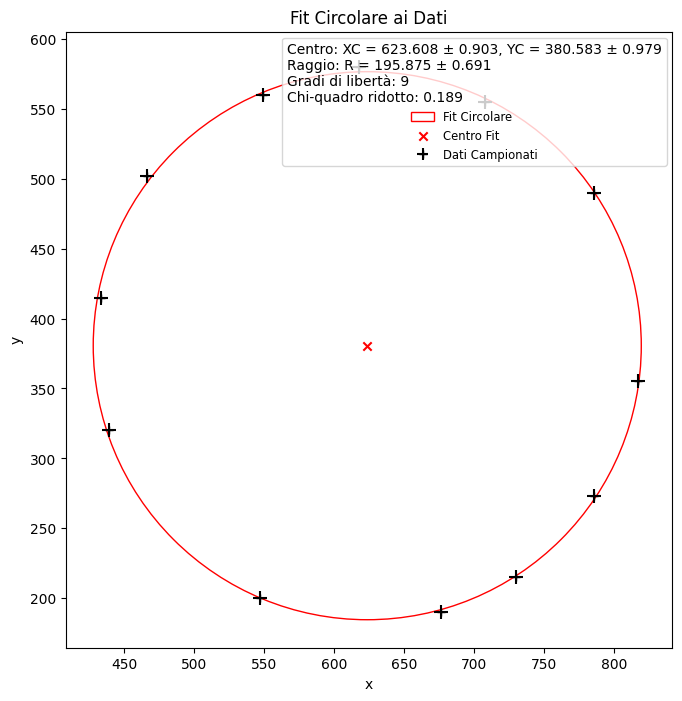

In [11]:
# Plot dei dati e del fit
fig, ax = plt.subplots(figsize=(8,8))
circle = plt.Circle((xc_fit, yc_fit), R_fit, color='r', fill=False, label='Fit Circolare')
ax.add_patch(circle)
ax.errorbar(x, y, xerr=d, yerr=d, fmt='k+', label='Dati Campionati') # Punti sperimentali in nero con croce
ax.scatter ([xc_fit], [yc_fit], color='red', marker='x', label='Centro Fit')
ax.set_aspect('equal')
plt.xlabel("x")
plt.ylabel("y")
plt.legend (title=fit_summary, loc='upper right', fontsize='small')
plt.title("Fit Circolare ai Dati")
plt.show()

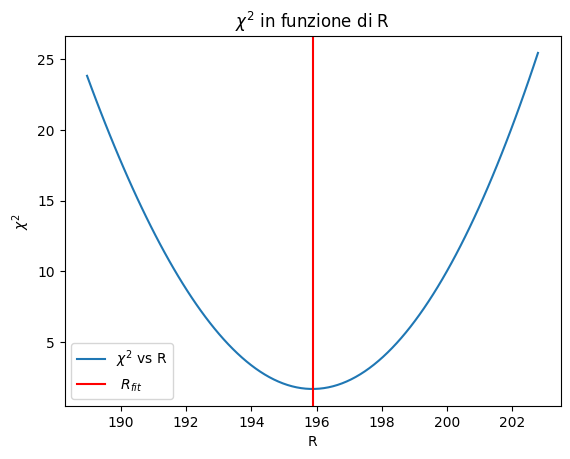

In [12]:
# Nuovo plot: Chi^2 in funzione di R 

R_values = np.linspace (R_fit - 10*errors [2], R_fit + 10*errors [2], 100)
chi2_values = [chi2_circle((xc_fit,yc_fit, R), x, y, d) for R in R_values]
plt.figure()
plt.plot(R_values, chi2_values, label=r"$ \chi^2$ vs R")
plt.axvline (R_fit, color='r', linestyle='-', label=r" $R_{fit}$")
plt.xlabel("R")
plt.ylabel(r"$\chi^2$")
plt.title(r"$\chi^2$ in funzione di R")
plt.legend ()
plt.show()

### Study stars (find coversion factor)

In [13]:
# Declination and ascension (in degrees)
arcturus = [19, 214]
regulus = [12, 152]
spica = [-11, 201]

arcturus_coords = [324, 446]
regulus_coords = [700, 60]
spica_coords = [606, 529]

Similar to how we locate a point on Earth using latitude and longitude, we locate stars using:

    Declination (δ) — like latitude, tells how far north or south a star is from the celestial equator. Measured in degrees.

    Right Ascension (α) — like longitude, tells the "left or right" position of a star. Measured in hours, minutes, and seconds (but can be converted to degrees).

In [14]:
def angular_distance(star_1, star_2):
    '''For each star give declination and ascension in degrees'''

    # Must change to radians
    dec1, ra1 = np.radians(star_1)
    dec2, ra2 = np.radians(star_2)

    # Apply spherical cosine formula
    cos_delta = (
        np.sin(dec1) * np.sin(dec2) +
        np.cos(dec1) * np.cos(dec2) * np.cos(ra1 - ra2)
    )

    delta = np.arccos(cos_delta)  # result in radians
    return delta

In [15]:
def pixel_distance(star_1, star_2):
    '''For each star five x and y coord'''
    return np.sqrt((star_1[0]-star_2[0])**2 + (star_1[1]-star_2[1])**2)

In [16]:
dist_pixels = [pixel_distance(arcturus_coords, regulus_coords),
               pixel_distance(arcturus_coords, spica_coords),
               pixel_distance(spica_coords, regulus_coords)
]

dist_angular = [angular_distance(arcturus, regulus), 
                angular_distance(arcturus, spica),
                angular_distance(regulus, spica)]

In [17]:
conversion_factor = [a/b for a,b in zip(dist_angular, dist_pixels)]
conv_fact = np.mean(conversion_factor)
err_conv_fact = np.std(conversion_factor)

In [18]:
print(f'factors: {conversion_factor}, \n'
      f'conversion factor: {conv_fact:.6f}  ± {err_conv_fact:.6f}')

factors: [np.float64(0.00193931271249552), np.float64(0.001936913797204452), np.float64(0.001963957176578413)], 
conversion factor: 0.001947  ± 0.000012


note: the factor converts pixels to RADIANS  

### Ice refractive index

In [19]:
# Save values with their uncertainty

R = (R_fit, errors[2])
conv_f = (conv_fact, err_conv_fact)

halo_ang = R[0] * conv_f[0]
err_halo_ang = halo_ang * np.sqrt((R[1]/R[0])**2 + (conv_f[1]/conv_f[0])**2)

halo = (halo_ang, err_halo_ang)

In [20]:
print(f'Radius: {R[0]:.2f} ± {R[1]:.2f} pixels \n'
    f'Halo: {halo[0]:.4f} ± {halo[1]:.4f} rad \n'
    f'Halo: {np.degrees(halo[0]):.4f} ± {np.degrees(halo[1]):.4f} °')


Radius: 195.87 ± 0.69 pixels 
Halo: 0.3813 ± 0.0027 rad 
Halo: 21.8478 ± 0.1573 °


In [21]:
import tensorflow as tf

def refraction_index(theta, A):
    # A should also be a tf.Tensor or constant, in radians
    return tf.math.sin((A + theta) / 2) / tf.math.sin(A / 2)

A = tf.constant(np.pi / 3, dtype=tf.float32)  # 60 degrees in radians

2025-05-01 10:29:51.202664: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-05-01 10:29:51.203717: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-05-01 10:29:51.210151: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-05-01 10:29:51.228743: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1746088191.259047    6502 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1746088191.26

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.1.3 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.




A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.1.3 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/usr/lib/python3/dist-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/usr/lib/python3/dist-packages/traitlets/config/application.py", line 982, in launch_instance
    app.start()
  File "/usr/lib/python3/dist-packages/ipykernel/kernelapp.py", line 739, in start
    self.io_loop.start()
  File "/usr/lib/python3/dist-packages/tornado/platform/asyncio.py", line 205, in s

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.1.3 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



2025-05-01 10:29:56.182974: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [22]:
import tensorflow as tf

theta = tf.Variable(halo_ang, dtype=tf.float32) 

with tf.GradientTape(persistent=True) as tape:
    tape.watch([theta])
    n = refraction_index(theta, A)

df_dtheta = tape.gradient(n, theta)

err_n = df_dtheta * err_halo_ang


In [23]:
print(f'Refractive index of ice: {n:.4f} ± {err_n:.4f}')

Refractive index of ice: 1.3101 ± 0.0021


### Compare refractive index of ice and water

**Gladstone-Dale law**

refraction power of a medium depends on its density  
$n-1 = k\rho$  

$\rho$: density  
k: the constant used in thermodynamics ???

therefore:  

$\frac{n_{ice} -1}{\rho _{ice}} = \frac{n_{water} -1}{\rho _{water}}$  

$n_{ice} = (n_{water} -1) \frac{\rho _{ice}}{\rho _{water}} +1 $



In [24]:
n_water = 1.33
rho_water = 0.98
rho_ice = 0.92
n_ice = (n_water-1)*(rho_ice/rho_water) +1

print(f'Refractive index of ice: n = {n_ice:.6}')

Refractive index of ice: n = 1.3098
